# Inspection capacity, timing and achievable detections

This notebook reproduces the four frozen QML/classical kernel configurations on the original three chronological test cohorts and compares them with low-information inspection policies. Results are empirical, retrospective counts; the oracle uses test outcomes solely as a mathematical upper bound. The 5%/20% budgets, chronological and product-family comparators, oracle calculations and matched logistic classifier are **post-hoc**. Within these three cohorts, the original 10% daily comparison was fixed before model scoring only for ProBayes; its cohort sizes and outcomes by day were known. Use the budgets for sensitivity analysis without selecting a preferred budget after seeing results.

**Question.** When the total inspection budget is fixed, how many defective units can a policy reach, and how many of those units does a scoring model actually find? The unit is a process sample for SECOM, a cycle for KAMP and a part for ProBayes.

A separate frozen temporal transfer evaluation on the November 2022 ProBayes campaign follows the main three-cohort analyses.

## Inputs and software

The recorded outputs use 64-bit Python 3.14.0 on Windows. To reproduce this environment in an isolated Python environment, install the versions below, start JupyterLab and run all cells in order.

```text
python -m pip install numpy==2.4.3 pandas==3.0.1 scipy==1.16.3 scikit-learn==1.8.0 threadpoolctl==3.6.0 matplotlib==3.10.7 ipython==9.11.0 ipykernel==7.2.0 jupyterlab==4.5.5
python -m jupyterlab
```

The precision analysis uses Python's built-in `decimal` module. The alternative original-Parquet reader for the November 2022 campaign additionally requires `python -m pip install pyarrow==23.0.1`. All quantum kernel evaluations use the ideal state-vector implementation below.

Local files may be placed next to this notebook or in `data/`. The notebook downloads missing inputs and verifies four SHA-256 digests for the main cohorts. The later-campaign cell separately checks its CSV by Git blob and SHA-256. The notebook contains the full model and evaluation code and does not read another notebook.

- McCann & Johnston, [SECOM (2008), UCI](https://doi.org/10.24432/C54305).
- Korean Ministry of SMEs and Startups, Korea AI Manufacturing Platform, *Injection Molding Machine AI Dataset* (2020), KAIST, UNIST and EPM Solutions. [CSV mirror and attribution](https://github.com/sanngrok/molding-defect-prediction).
- Lambers, Schüder & Krauß (2022), [Injection-Molding Production Data with Quality Labels, v2](https://doi.org/10.23728/b2share.4c5692b886db419180f716acf895bf06). The analyzed file is a [pinned third-party CSV conversion](https://github.com/ar363/plastic-injection-moulding-quality-detection/blob/8741433081eeff1d628d749861aedaacb2a6fa6e/data/dataset.csv).

In [1]:
from dataclasses import dataclass
from pathlib import Path
from importlib.metadata import version
from io import BytesIO
from zipfile import ZipFile
from urllib.request import Request, urlopen
import base64, hashlib, json, platform, warnings

import numpy as np
import pandas as pd
import scipy, sklearn
from scipy.linalg import hadamard
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

print(platform.system(), platform.machine(), "Python", platform.python_version(),
      "NumPy", np.__version__, "pandas", pd.__version__, "SciPy", scipy.__version__, "sklearn", sklearn.__version__)
print("threadpoolctl", version("threadpoolctl"), "Matplotlib", version("matplotlib"),
      "IPython", version("ipython"), "ipykernel", version("ipykernel"))

SECOM = "https://archive.ics.uci.edu/static/public/179/secom.zip"
KAMP = "https://api.github.com/repos/sanngrok/molding-defect-prediction/git/blobs/91c63810c331a88c73e4ecd491429f35e1635199"
PROBAYES = "https://raw.githubusercontent.com/ar363/plastic-injection-moulding-quality-detection/8741433081eeff1d628d749861aedaacb2a6fa6e/data/dataset.csv"
DIGEST = {
    "secom.data": "4503bdb42e63687d1c7586bdc1796df9a7cb5ae9cc9c0443d84957a446de3aaf",
    "secom_labels.data": "2fb2e8b5dfe77ba96ecf0960ff00f2ba9311795383a8342d4588a7cb37c816ef",
    "labeled_data.csv": "e8d375c8e0c2cdfc309baf01ac2203fc2edb6e9728e836119042f9670cd46b51",
    "probayes.csv": "515ae0548520bdcd04609b5def646246122d116ab72ae07e058e206c8319142e",
}
local_dirs = [Path("."), Path("data")]
def fetch(url):
    request = Request(url, headers={"User-Agent":"QML-inspection-benchmark"})
    with urlopen(request, timeout=90) as response:
        return response.read()

def load_inputs():
    raw = {}
    for name in DIGEST:
        aliases = [name, "dataset.csv"] if name == "probayes.csv" else [name]
        path = next((directory/alias for directory in local_dirs for alias in aliases
                     if (directory/alias).is_file()), None)
        if path:
            raw[name] = path.read_bytes()
    if "secom.data" not in raw or "secom_labels.data" not in raw:
        with ZipFile(BytesIO(fetch(SECOM))) as archive:
            for member in archive.namelist():
                if Path(member).name in ("secom.data", "secom_labels.data"):
                    raw[Path(member).name] = archive.read(member)
    if "labeled_data.csv" not in raw:
        raw["labeled_data.csv"] = base64.b64decode(json.loads(fetch(KAMP))["content"])
    if "probayes.csv" not in raw:
        raw["probayes.csv"] = fetch(PROBAYES)
    for name, expected in DIGEST.items():
        assert hashlib.sha256(raw[name]).hexdigest() == expected, f"Input hash differs: {name}"
    return raw

@dataclass
class Cohort:
    x_train: object
    y_train: np.ndarray
    x_test: object
    y_test: np.ndarray
    time: pd.DatetimeIndex
    family_train: object = None
    family_test: object = None
    settings: object = None

raw = load_inputs()

Windows AMD64 Python 3.14.0 NumPy 2.4.3 pandas 3.0.1 SciPy 1.16.3 sklearn 1.8.0
threadpoolctl 3.6.0 Matplotlib 3.10.7 IPython 9.11.0 ipykernel 7.2.0


In [2]:
def prepare_secom(raw):
    x = np.loadtxt(BytesIO(raw["secom.data"]))
    data = [line.split(maxsplit=1) for line in raw["secom_labels.data"].decode("ascii").splitlines()]
    target = np.array([int(label) for label, t in data])
    assert set(target) == {-1, 1}
    y = (target == 1).astype(int)
    time = pd.to_datetime([t.strip('"') for label, t in data], format="%d/%m/%Y %H:%M:%S")
    fit = (time >= "2008-07-01") & (time < "2008-10-01")
    test = (time >= "2008-10-01") & (time < "2008-11-01")
    # Keep original file order for tied model scores; chronology control uses actual timestamps.
    return Cohort(x[fit], y[fit], x[test], y[test], time[test])

def prepare_kamp(raw):
    frame = pd.read_csv(BytesIO(raw["labeled_data.csv"]), encoding="utf-8-sig", keep_default_na=False, dtype=str)
    parts = frame.drop_duplicates().copy()
    parts["family"] = parts["PART_NAME"].str.split().str[0]
    parts = parts[parts["EQUIP_CD"].eq("S14") & parts["family"].isin(["CN7","RG3"])].copy()
    parts["TimeStamp"] = pd.to_datetime(parts["TimeStamp"], errors="raise")
    sensors = list(frame.columns[frame.columns.get_loc("Injection_Time"):])
    features = [feature for feature in sensors if feature != "Average_Screw_RPM"]
    parts[sensors] = parts[sensors].apply(pd.to_numeric, errors="raise")
    keys = ["TimeStamp", "EQUIP_CD", "family"]
    grouped = parts.groupby(keys, sort=True)
    assert len(frame)==7996 and len(frame.drop_duplicates())==5232 and len(parts)==5230
    assert set(parts.PassOrFail) == {"N","Y"} and len(sensors)==36
    assert grouped[sensors].nunique(dropna=False).le(1).all().all()
    assert not parts.duplicated(keys+["PART_NAME"]).any() and grouped.size().max()==2
    x = grouped[features].first()
    y = parts.PassOrFail.eq("N").groupby([parts[k] for k in keys]).any().reindex(x.index)
    assert y.notna().all()
    time = x.index.get_level_values("TimeStamp")
    family = x.index.get_level_values("family").to_numpy()
    days = time.normalize().unique().sort_values()
    fit = time.normalize() < days[-5]
    y = y.to_numpy(dtype=int)
    return Cohort(x.loc[fit],y[fit],x.loc[~fit],y[~fit],time[~fit],family[fit],family[~fit])

def prepare_probayes(raw):
    features = ["QUA_CycleTime","QUA_InjectionTime","QUA_PlastificationTime","QUA_CushionVolume",
                "QUA_InjectionPressureMax","QUA_TransferPressure","QUA_TransferStroke","QUA_OilTemperature"]
    meta = ["MET_MachineCycleID","MET_TimeCycleStart","MET_ExperimentNumber","MET_MaterialName","LBL_NOK"]
    df = pd.read_csv(BytesIO(raw["probayes.csv"]), usecols=features+meta)
    df["time"] = pd.to_datetime(df.MET_TimeCycleStart,errors="raise")
    assert df.time.is_unique and df.time.notna().all() and df.MET_MachineCycleID.is_unique
    df = df.sort_values(["time","MET_MachineCycleID"],kind="stable").reset_index(drop=True)
    day = df.time.dt.strftime("%Y-%m-%d")
    assert sorted(day.unique().tolist()) == ["2021-12-07","2021-12-15","2022-03-17"]
    fit = day.eq("2021-12-07")
    y = df.LBL_NOK.to_numpy(dtype=int)
    block = day + " / " + df.MET_ExperimentNumber.astype(str)
    return Cohort(df.loc[fit,features],y[fit],df.loc[~fit,features],y[~fit],
                  pd.DatetimeIndex(df.loc[~fit,"time"]),settings=block.loc[~fit].to_numpy())

cohorts = {"SECOM":prepare_secom(raw),"KAMP":prepare_kamp(raw),"ProBayes":prepare_probayes(raw)}
expected_counts = {"SECOM":(1208,82,359,22,17),"KAMP":(1741,44,883,8,5),"ProBayes":(204,95,360,60,2)}
for name,cohort in cohorts.items():
    counts = (len(cohort.y_train),int(cohort.y_train.sum()),len(cohort.y_test),int(cohort.y_test.sum()),len(cohort.time.normalize().unique()))
    assert counts==expected_counts[name]
    print(name,"training n / defects, test n / defects / dates:",counts)

SECOM training n / defects, test n / defects / dates: (1208, 82, 359, 22, 17)
KAMP training n / defects, test n / defects / dates: (1741, 44, 883, 8, 5)
ProBayes training n / defects, test n / defects / dates: (204, 95, 360, 60, 2)


## Classifiers and controls

Every learned model uses train-only preprocessing, balanced classes, and a common temporal fit/test split. Full-input and PCA4 RBF SVMs use relative gamma multipliers 0.25 and 1, respectively. Both fidelity kernels share two layers and phase scale 0.5. The original kernels were fixed from SECOM development. The additional L2-regularized PCA4 logistic regression uses the identical PCA representation and C=1 for all datasets, without additional validation or test-based selection.

The chronology-only rule selects the earliest available units in the relevant pool, breaking repeated timestamps by original row order. For KAMP only, the product-family rule ranks by the historical training-cycle failure rate of each family. Family ties follow timestamp, machine and family order. Both rules ignore sensor features. These simple policies do not have advance knowledge of which future units fail.

In [3]:
def fit_rbf(x_train, x_test, y_train, multiplier):
    gamma = multiplier / (x_train.shape[1] * x_train.var())
    model = SVC(C=1, class_weight="balanced", kernel="rbf", gamma=gamma)
    return model.fit(x_train, y_train).decision_function(x_test)

# Two repeated blocks: H on each qubit, RZ(x_j), optionally RZZ(x_j*x_{j+1}) on neighbors.
z = 1 - 2 * ((np.arange(16)[:, None] >> np.arange(3, -1, -1)) & 1)
zz = z[:, :-1] * z[:, 1:]
h = hadamard(16) / 4.0

def statevectors(x, coupled):
    phase = x @ z.T
    if coupled:
        phase += (x[:, :-1] * x[:, 1:]) @ zz.T
    d = np.exp(-0.5j * phase)
    states = ((d / 4.0) @ h) * d
    np.testing.assert_allclose(np.linalg.norm(states, axis=1), 1.0, atol=1e-12)
    return states

def fidelity_blocks(left, right):
    gram = np.empty((len(left), len(right)), dtype=np.float64)
    adjoint = right.conj().T
    for start in range(0, len(left), 192):
        block = slice(start, start + 192)
        gram[block] = np.abs(left[block] @ adjoint)**2
    return gram

def fit_quantum(train_states, test_states, labels):
    gram = fidelity_blocks(train_states, train_states)
    np.testing.assert_allclose(gram.diagonal(), 1, atol=1e-12)
    np.testing.assert_allclose(gram[:32], gram[:, :32].T, atol=1e-12)
    model = SVC(C=1, kernel="precomputed", class_weight="balanced")
    model.fit(gram, labels)
    del gram
    # Score in small batches to cap peak memory.
    return np.concatenate([model.decision_function(fidelity_blocks(test_states[i:i+192], train_states))
                           for i in range(0, len(test_states), 192)])

def run_models(train_x, labels, test_x):
    process = make_pipeline(SimpleImputer(strategy="median"), VarianceThreshold(), StandardScaler())
    full_train = process.fit_transform(train_x)
    full_test = process.transform(test_x)
    pca = PCA(n_components=4, svd_solver="full")
    pc_train = pca.fit_transform(full_train)
    pc_test = pca.transform(full_test)
    print("Retained process features:", full_train.shape[1], "| PCA4 variance:", pca.explained_variance_ratio_.sum())
    pred = {"Full RBF": fit_rbf(full_train, full_test, labels, 0.25),
            "PCA4 RBF": fit_rbf(pc_train, pc_test, labels, 1)}
    phase_scale = 0.5 / np.sqrt(np.mean(pc_train**2))
    for name, coupled in (("Q4 + RZZ", True), ("Q4 no RZZ", False)):
        train_states = statevectors(pc_train * phase_scale, coupled)
        test_states = statevectors(pc_test * phase_scale, coupled)
        pred[name] = fit_quantum(train_states, test_states, labels)
    # Prespecified here as a post-hoc linear control; all its inputs match the quantum models.
    logistic = LogisticRegression(C=1.0, class_weight="balanced", solver="lbfgs", max_iter=2000, tol=1e-8)
    pred["PCA4 logistic"] = logistic.fit(pc_train, labels).decision_function(pc_test)
    assert all(np.isfinite(a).all() and len(a) == len(test_x) for a in pred.values())
    return pred

In [4]:
original_models = ["Full RBF","PCA4 RBF","Q4 + RZZ","Q4 no RZZ"]
all_scores = {}
ap_rows = []
families = None
with threadpool_limits(limits=1), warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Skipping features without any observed values.*", category=UserWarning)
    for name,c in cohorts.items():
        scores = run_models(c.x_train,c.y_train,c.x_test)
        digest = hashlib.sha256(np.stack([scores[m] for m in original_models]).astype("<f8").tobytes()).hexdigest()
        print(name,"original-four decision score SHA-256:",digest)
        # Unique rank gives a deterministic no-sensor policy; source row breaks duplicate timestamps.
        chronology = np.argsort(c.time.to_numpy(),kind="stable")
        chronological_ranks = np.empty(len(chronology),dtype=np.int64)
        chronological_ranks[chronology] = np.arange(len(chronology))
        scores["Chronology only"] = -chronological_ranks
        if c.family_train is not None:
            counts = pd.DataFrame({"family":c.family_train,"defect":c.y_train}).groupby("family").defect.agg(["size","sum","mean"])
            families = counts.copy()
            scores["Family only"] = pd.Series(c.family_test).map(counts["mean"]).to_numpy()
        for method,score in scores.items():
            ap_rows.append([name,method,average_precision_score(c.y_test,score)])
        all_scores[name] = scores
ap_table = pd.DataFrame(ap_rows,columns=["dataset","method","pooled_ap"])
print("\nKAMP family defect rates using training data only:")
print(families.to_string())

Retained process features: 468 | PCA4 variance: 0.1519236724745431
SECOM original-four decision score SHA-256: 85f58176c4c3c7d9c2fa989fd68755c72c59d2741c82592a77d37fdee4d1801f
Retained process features: 24 | PCA4 variance: 0.956829463522357
KAMP original-four decision score SHA-256: fdc43bdb618b135b694ef2c72fc618fbe3bb3cfab5b6a4146756bbebbb63d0c7
Retained process features: 8 | PCA4 variance: 0.9767549376330416
ProBayes original-four decision score SHA-256: 3d7ea3998387304da4da02f0e9188f78f568aaff3c0aa7574567c84a5a7be868

KAMP family defect rates using training data only:
        size  sum      mean
family                     
CN7     1150   19  0.016522
RG3      591   25  0.042301


## Inspection policies and ceilings

For each test set with N units and capacity p%, use B = ceil(p × N / 100). The pooled policy ranks all available test units. The daily policy rounds B × daily units / N down and assigns leftover slots to the largest fractional remainders, earliest date first for remainder ties. It uses completed daily batch sizes, including days receiving zero slots. A test score is frozen across all capacity levels.

If a policy assigns q inspections to a group of n units with f defects, uniform selection has expected detections qf/n; a perfect ordering reaches at most min(q,f). Both quantities sum over independent selection groups (days or the entire cohort), regardless of statistical dependence among their labels. The oracle is not deployable. For each tie in a model score, we retain the original deterministic tie rule for the observed count (SECOM source rows; KAMP and ProBayes chronological). We also report the expectation and bounds obtained by varying only the exact decision-score ties. Capacity sensitivity is descriptive given the small number of independent faulty production settings.

In [5]:
def make_groups(time, budget, policy):
    idx = np.arange(len(time))
    if policy == "pooled":
        return [("all dates",idx,budget)]
    date = time.normalize()
    days = date.unique().sort_values()
    rows = [np.flatnonzero(date==d) for d in days]
    sizes = np.array([len(r) for r in rows],dtype=int)
    quotas, remainders = np.divmod(budget*sizes,len(time))
    left = int(budget-quotas.sum())
    quotas[np.argsort(-remainders,kind="stable")[:left]] += 1
    assert quotas.sum()==budget and (quotas<=sizes).all()
    return [(d.strftime("%Y-%m-%d"),r,int(q)) for d,r,q in zip(days,rows,quotas)]

def inspect_group(score,labels,rows,q):
    # Bounds and expectation reflect exact equality in the floating-point decision function.
    if not q:
        return np.array([],dtype=int), 0.0, 0, 0, 0, 0
    ind = rows[np.argsort(-score[rows],kind="stable")]
    picks = ind[:q]
    cutoff = score[picks[-1]]
    tied = rows[score[rows]==cutoff]
    above = rows[score[rows]>cutoff]
    fixed = int(labels[above].sum())
    left = q-len(above)
    positives = int(labels[tied].sum())
    expected = fixed+left*positives/len(tied)
    lower = fixed+max(0,left-(len(tied)-positives))
    upper = fixed+min(left,positives)
    return picks, expected, lower, upper, len(tied), left

def evaluate_scenario(dataset, cohort, scores, percent, policy):
    y = cohort.y_test
    budget = (len(y)*percent+99)//100
    groups = make_groups(cohort.time,budget,policy)
    random_hits = sum(q*y[r].mean() for _,r,q in groups)
    ceiling = sum(min(q,int(y[r].sum())) for _,r,q in groups)
    assert random_hits <= ceiling+1e-10
    common = dict(dataset=dataset,percent=percent,policy=policy,slots=budget,
                  units=len(y),defects=int(y.sum()),random_expected=float(random_hits),oracle=int(ceiling))
    totals, detail = [], []
    for method,score in scores.items():
        picks_list,means,lower,upper = [],[],[],[]
        for day,rows,q in groups:
            picks,mean,lo,hi,n_tied,in_tie = inspect_group(score,y,rows,q)
            hits = int(y[picks].sum())
            assert lo<=hits<=hi<=min(q,int(y[rows].sum())) and lo-1e-10<=mean<=hi+1e-10
            picks_list.append(picks)
            means.append(mean)
            lower.append(lo)
            upper.append(hi)
            detail.append(dict(dataset=dataset,percent=percent,policy=policy,group=day,method=method,
                               units=len(rows),slots=q,defects=int(y[rows].sum()),hits=hits,tie_expected=mean,
                               tie_min=lo,tie_max=hi,at_cutoff=n_tied,slots_in_boundary=in_tie))
        selected = np.concatenate(picks_list)
        assert len(np.unique(selected))==budget
        hits = int(y[selected].sum())
        blocks = np.nan if cohort.settings is None else len(set(cohort.settings[selected[y[selected]==1]]))
        totals.append(dict(**common,method=method,hits=hits,recall=(hits/y.sum() if y.sum() else np.nan),positive_blocks=blocks,
                           tie_expected=sum(means),tie_min=sum(lower),tie_max=sum(upper)))
    return totals, detail

records, groups_record = [], []
for name,c in cohorts.items():
    for percent in (5,10,20):
        for policy in ("pooled","daily"):
            totals, details = evaluate_scenario(name,c,all_scores[name],percent,policy)
            records.extend(totals)
            groups_record.extend(details)
summary = pd.DataFrame(records)
group_detail = pd.DataFrame(groups_record)
primary_models = original_models + ["PCA4 logistic","Chronology only","Family only"]
def result_table(records):
    wide = records.pivot(index=["dataset","percent","policy","slots","defects","random_expected","oracle"],
                         columns="method",values="hits")
    return wide.reindex(columns=primary_models).astype("Int64").reset_index().rename_axis(None,axis=1)

print(result_table(summary).to_string(index=False,na_rep="—",float_format=lambda x:f"{x:.2f}"))


 dataset  percent policy  slots  defects  random_expected  oracle  Full RBF  PCA4 RBF  Q4 + RZZ  Q4 no RZZ  PCA4 logistic  Chronology only  Family only
    KAMP        5  daily     45        8             0.44       3         1         0         0          1              0                0            0
    KAMP        5 pooled     45        8             0.41       8         7         7         7          7              7                0            7
    KAMP       10  daily     89        8             0.88       5         1         0         0          1              0                0            0
    KAMP       10 pooled     89        8             0.81       8         7         7         7          7              7                0            7
    KAMP       20  daily    177        8             1.56       8         2         0         0          1              0                0            0
    KAMP       20 pooled    177        8             1.60       8         8         7   

In [6]:
# These counts are recorded from the two earlier reports, before these sensitivity analyses.
expected10 = {
    ("SECOM","pooled"):[3,1,3,2], ("SECOM","daily"):[3,1,4,2],
    ("KAMP","pooled"):[7,7,7,7], ("KAMP","daily"):[1,0,0,1],
    ("ProBayes","pooled"):[24,19,12,12], ("ProBayes","daily"):[21,24,2,15],
}
for (name,policy),expected in expected10.items():
    subset = summary.query("dataset==@name and percent==10 and policy==@policy").set_index("method")
    np.testing.assert_array_equal(subset.loc[original_models,"hits"].to_numpy(),expected)
np.testing.assert_array_equal(summary.query("percent==10 and policy=='daily' and method=='Chronology only'").hits.to_numpy(),[2,0,12])
np.testing.assert_array_equal(summary.query("percent==10 and policy=='daily' and method=='Chronology only'").oracle.to_numpy(),[16,5,32])
np.testing.assert_allclose(summary.query("dataset=='ProBayes' and percent==10 and policy=='daily' and method=='PCA4 RBF'").tie_expected.iloc[0],12+16*12/132)
print("Reproduced all 24 earlier 10% model/inspection counts.")
print("\nProBayes daily cutoff sensitivities:")
print(summary.query("dataset=='ProBayes' and policy=='daily' and method!='Chronology only'")[
    ["percent","method","hits","tie_min","tie_expected","tie_max","positive_blocks"]].to_string(index=False,float_format=lambda x:f"{x:.2f}"))
print("\nAverage precision for each complete score ranking:")
print(ap_table.pivot(index="dataset",columns="method",values="pooled_ap").reindex(columns=primary_models).to_string(na_rep="—",float_format=lambda x:f"{x:.5f}"))

Reproduced all 24 earlier 10% model/inspection counts.

ProBayes daily cutoff sensitivities:
 percent        method  hits  tie_min  tie_expected  tie_max  positive_blocks
       5      Full RBF    13        5          5.89       13             2.00
       5      PCA4 RBF    16        8          8.73       16             2.00
       5      Q4 + RZZ     0        0          0.00        0             0.00
       5     Q4 no RZZ    10       10         10.00       10             1.00
       5 PCA4 logistic    10       10         10.00       10             1.00
      10      Full RBF    21        9         10.78       21             2.00
      10      PCA4 RBF    24       12         13.45       24             2.00
      10      Q4 + RZZ     2        2          2.00        2             1.00
      10     Q4 no RZZ    15       15         15.00       15             2.00
      10 PCA4 logistic    12       12         12.00       12             1.00
      20      Full RBF    36       24         27.

## Original ProBayes analysis specification

The supplementary file `evidence/probayes_original_protocol.json` contains the canonical JSON bytes extracted from the stored `protocol` object in the historical `ProBayes_Fixed_Inspection.ipynb` (cell index 4, counted from zero). Its SHA-256, `1ad08ae6d811ff98da622a2acadee00e9366c1a5e9167d3c24d4946306c3d2e3`, matches the digest printed in that cell. The digest verifies the recovered text against that output. Timing is documented by an internal record and was not externally registered or independently time-stamped.

The primary comparison is the number of detected defective parts for the coupled quantum kernel minus PCA4 RBF, with fixed daily inspection slots of 20 and 16. Removing the pair rotations and counting distinct defective date–settings reached were secondary comparisons. The researchers already knew the dates, material types, failure totals, clustering and descriptive input shifts before model scoring. The tie-sensitive probability of reaching each positive setting below is an exploratory extension of the original secondary coverage endpoint.

## Primary ProBayes contrast at 10% daily capacity

The contrast uses the same parts and inspection slots for both models. Differences are coupled kernel minus four-component RBF. The tie limits enumerate attainable differences for these observed scores and labels. They are separate from sampling uncertainty.

In [7]:
# Primary ProBayes contrast on the two original evaluation dates.
primary = group_detail.query("dataset == 'ProBayes' and policy == 'daily' and percent == 10")
coupled = primary.loc[primary.method == "Q4 + RZZ"].set_index("group").sort_index()
classical = primary.loc[primary.method == "PCA4 RBF"].set_index("group").sort_index()
np.testing.assert_array_equal(coupled.index, classical.index)
np.testing.assert_array_equal(coupled[["slots", "defects"]], classical[["slots", "defects"]])
# Coupled detections are invariant to cutoff ties on both days. Subtracting
# the classical best/worst counts therefore yields attainable endpoints.
np.testing.assert_array_equal(coupled.tie_min, coupled.tie_max)
primary_daily = pd.DataFrame({
    "slots": coupled.slots,
    "defects": coupled.defects,
    "coupled_hits": coupled.hits,
    "classical_hits": classical.hits,
    "observed_difference": coupled.hits - classical.hits,
    "uniform_tie_difference": coupled.tie_expected - classical.tie_expected,
    "tie_min_difference": coupled.tie_min - classical.tie_max,
    "tie_max_difference": coupled.tie_max - classical.tie_min,
})
primary_daily.loc["All dates"] = primary_daily.sum()
count_columns = primary_daily.columns.drop("uniform_tie_difference")
primary_daily = primary_daily.astype({name: int for name in count_columns})
np.testing.assert_array_equal(primary_daily.observed_difference, [-10, -12, -22])
np.testing.assert_array_equal(primary_daily.tie_min_difference, [-10, -12, -22])
np.testing.assert_array_equal(primary_daily.tie_max_difference, [-10, 0, -10])
np.testing.assert_allclose(primary_daily.uniform_tie_difference, [-10, -16/11, -126/11])
combined = primary_daily.loc["All dates"]
recall_difference_pp = 100 * combined.observed_difference / combined.defects
print("Original ProBayes daily 10%: Q4 with RZZ minus PCA4 RBF")
print(primary_daily.to_string(float_format=lambda v: f"{v:.4f}"))
print(f"Observed recall difference across both dates: {recall_difference_pp:.4f} percentage points")

Original ProBayes daily 10%: Q4 with RZZ minus PCA4 RBF
            slots  defects  coupled_hits  classical_hits  observed_difference  uniform_tie_difference  tie_min_difference  tie_max_difference
group                                                                                                                                        
2021-12-15     20       48             2              12                  -10                -10.0000                 -10                 -10
2022-03-17     16       12             0              12                  -12                 -1.4545                 -12                   0
All dates      36       60             2              24                  -22                -11.4545                 -22                 -10
Observed recall difference across both dates: -36.6667 percentage points


## Positive inspection outcomes by experimental setting

Within the two original ProBayes dates, the following table identifies which defective parts are shared by the two prespecified rankings under chronological tie resolution. This post hoc breakdown lists all experimental settings that contained target defects. Each ranking is evaluated separately at its original quota.

In [8]:
# Exploratory attribution of the original ProBayes daily top-10% selections.
# Setting identifiers come from MET_ExperimentNumber in the pinned CSV conversion.
def positive_setting_overlap(cohort, model_scores):
    labels = cohort.y_test
    budget = (len(labels) * 10 + 99) // 100
    groups = make_groups(cohort.time, budget, "daily")
    picked = {}
    for method in ("Q4 + RZZ", "PCA4 RBF"):
        mask = np.zeros(len(labels), dtype=bool)
        for _, indices, slots in groups:
            selected = inspect_group(model_scores[method], labels, indices, slots)[0]
            mask[selected] = True
        assert int(mask.sum()) == budget
        picked[method] = mask
    quantum, classical = picked["Q4 + RZZ"], picked["PCA4 RBF"]
    parts = pd.DataFrame({
        "date": cohort.time.strftime("%Y-%m-%d"),
        "setting": [block.split(" / ", 1)[1] for block in cohort.settings],
        "defects": labels,
        "q4_rzz_hits": quantum * labels,
        "pca4_rbf_hits": classical * labels,
        "shared_hits": (quantum & classical) * labels,
    })
    totals = parts.groupby(["date", "setting"], sort=True)
    return totals.sum().assign(units=totals.size()).query("defects > 0").reset_index()[
        ["date", "setting", "units", "defects", "q4_rzz_hits", "pca4_rbf_hits", "shared_hits"]
    ]

probayes_setting_overlap = positive_setting_overlap(cohorts["ProBayes"], all_scores["ProBayes"])
np.testing.assert_array_equal(
    probayes_setting_overlap[["defects","q4_rzz_hits","pca4_rbf_hits","shared_hits"]].sum(),
    [60, 2, 24, 0],
)
print(probayes_setting_overlap.to_string(index=False))

      date setting  units  defects  q4_rzz_hits  pca4_rbf_hits  shared_hits
2021-12-15     A02     12       12            2              0            0
2021-12-15     A04     12       12            0              0            0
2021-12-15     A10     12       12            0              0            0
2021-12-15     A12     12       12            0             12            0
2022-03-17     A20     12       12            0             12            0


## SECOM October paired date bootstrap

This reproduces the interval for the original pooled 10% contrast on October SECOM. Keeping training and scores fixed, each draw resamples 17 dates with replacement. Ranked selection uses the ceiling of 10% of the resulting units. Zero-failure draws are omitted. The two percentile limits use the same draws for both models.

In [9]:
# SECOM October, original pooled contrast. Resample test dates with fixed scores.
def secom_paired_bootstrap(cohort, scores, *, n_draws=2000, seed=20261123):
    labels = cohort.y_test
    dates = cohort.time.normalize().to_numpy()
    groups = [np.flatnonzero(dates == day) for day in np.unique(dates)]
    quantum_scores = scores["Q4 + RZZ"]
    classical_scores = scores["PCA4 RBF"]

    def paired_difference(rows):
        outcomes = labels[rows]
        slots = (len(rows) + 9) // 10
        # rows are in original file order, including repeated observations.
        def score_metrics(prediction):
            sample_scores = prediction[rows]
            ranked = np.argsort(-sample_scores, kind="stable")
            hits = outcomes[ranked[:slots]].sum()
            return np.array([100 * hits / outcomes.sum(),
                             average_precision_score(outcomes, sample_scores)])

        return score_metrics(quantum_scores) - score_metrics(classical_scores)

    rng = np.random.default_rng(seed)
    differences = []
    for _ in range(n_draws):
        sampled_dates = rng.integers(0, len(groups), size=len(groups))
        rows = np.sort(np.concatenate([groups[d] for d in sampled_dates]), kind="stable")
        if labels[rows].sum() > 0:
            differences.append(paired_difference(rows))
    if not differences:
        raise ValueError("No bootstrap draws contained a failure.")
    return {
        "dates": len(groups),
        "draws": n_draws,
        "usable": len(differences),
        "observed": paired_difference(np.arange(len(labels))),
        "interval": np.quantile(differences, [0.025, 0.975], axis=0),
    }


secom_bootstrap = secom_paired_bootstrap(cohorts["SECOM"], all_scores["SECOM"])
print("SECOM pooled Q4 with RZZ minus PCA4 RBF; observed differences and 95% date-bootstrap intervals")
print(f"{secom_bootstrap['dates']} dates; {secom_bootstrap['usable']}/{secom_bootstrap['draws']} usable draws")
for col, metric in enumerate(["Recall (percentage points)", "Average precision"]):
    lo, hi = secom_bootstrap["interval"][:, col]
    print(f"{metric}: {secom_bootstrap['observed'][col]:.6f} [{lo:.6f}, {hi:.6f}]")

SECOM pooled Q4 with RZZ minus PCA4 RBF; observed differences and 95% date-bootstrap intervals
17 dates; 2000/2000 usable draws
Recall (percentage points): 9.090909 [-8.695652, 25.000000]
Average precision: 0.017316 [-0.000584, 0.073225]


## Daily inspection across budgets

The hollow circle and the smaller cross remain separately visible whenever both classifiers detect the same number of defects. Each dotted line gives an achievable upper bound using the experimental labels and daily quotas. Axis scales vary by cohort. The plotted points are descriptive counts at the three defined capacities. Rendering requires Matplotlib and IPython. Set `figure_path` to save the 400 dpi image to a file.

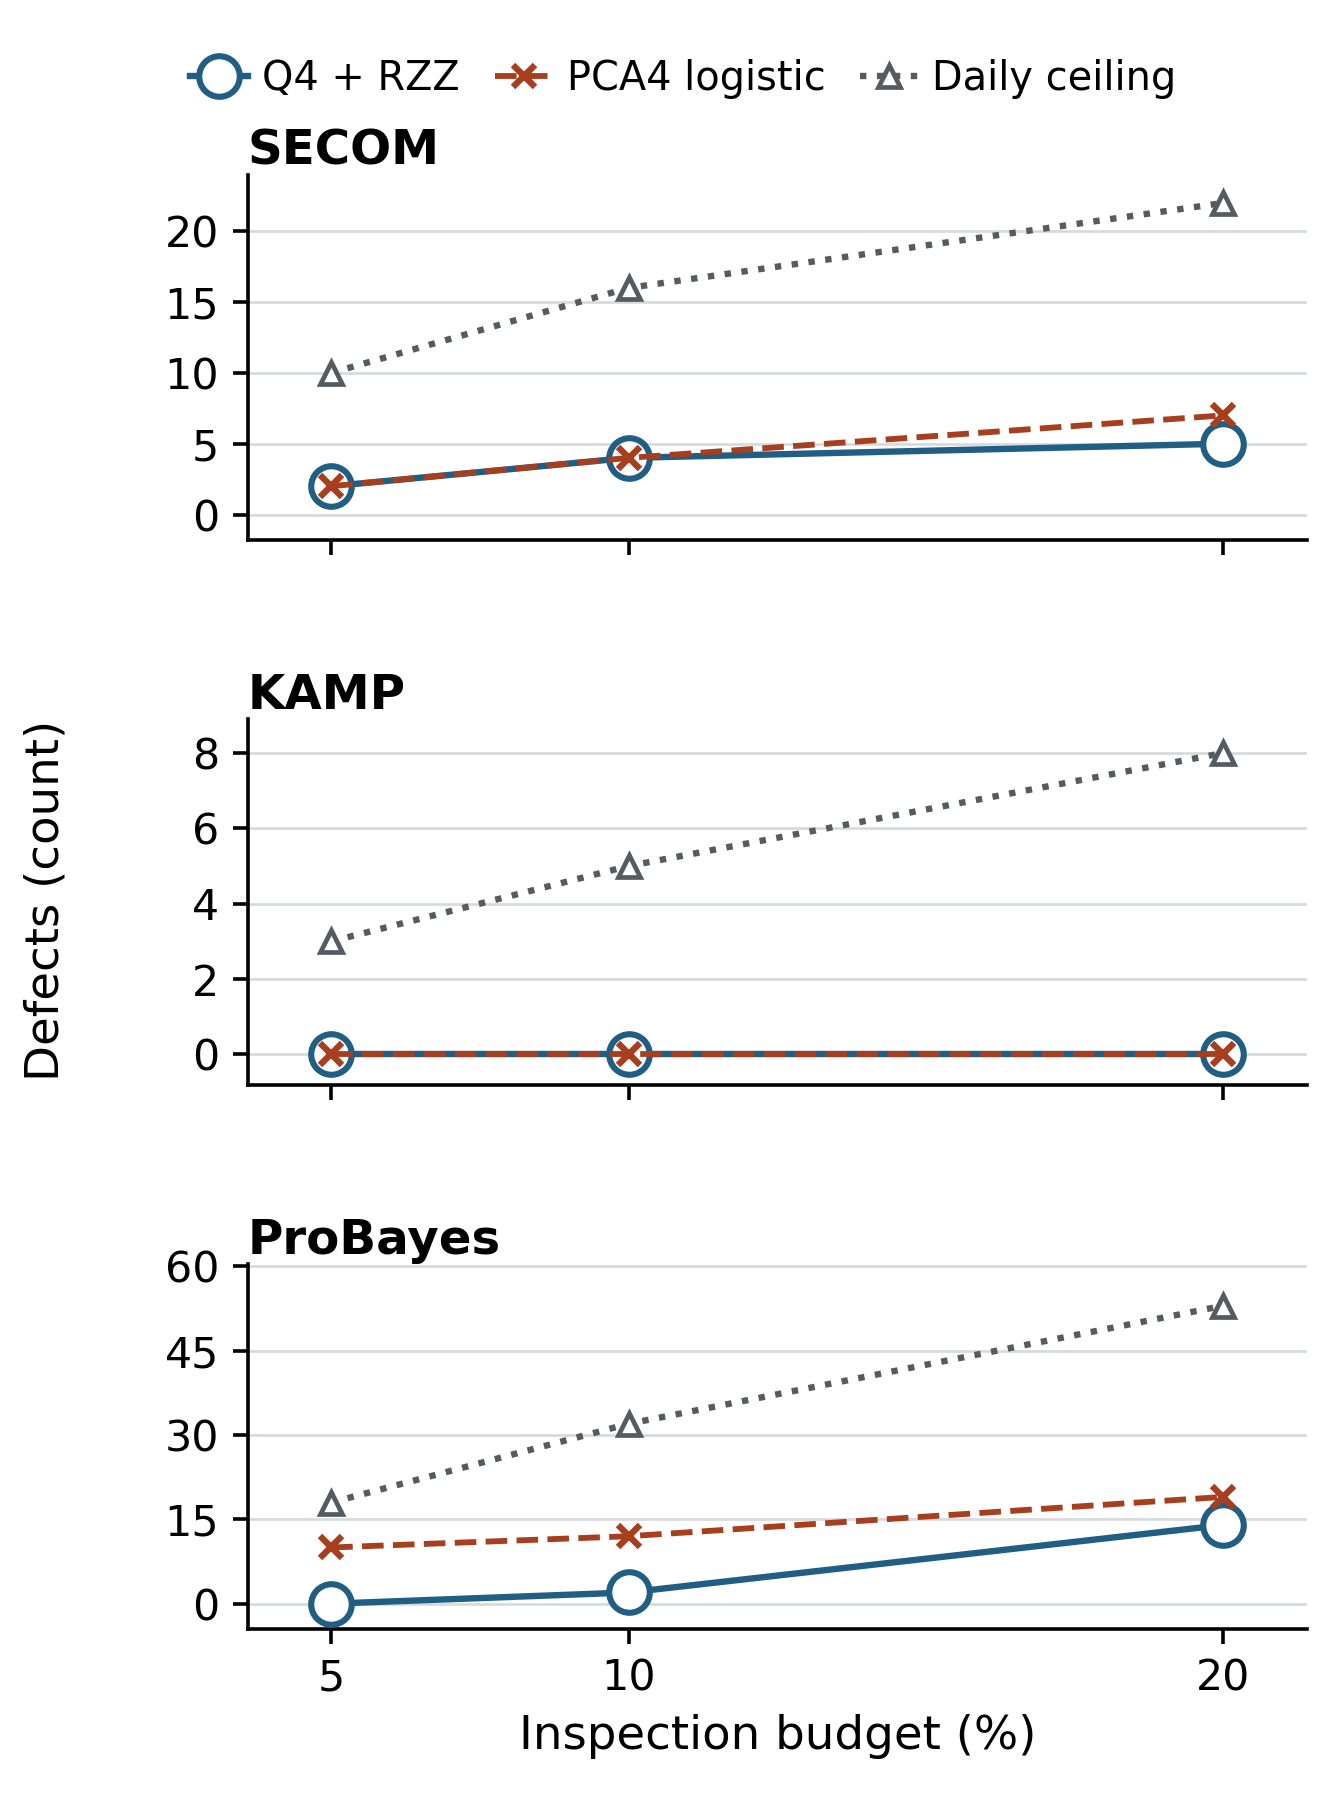

In [10]:
# Optional output path. Default renders only in the notebook.
figure_path = None  # e.g. Path("budget_sensitivity.png")
import os
from tempfile import TemporaryDirectory
# Use a writable font cache in restricted new kernels.
if "MPLCONFIGDIR" not in os.environ:
    figure_cache = TemporaryDirectory(prefix="qml-inspection-matplotlib-")
    os.environ["MPLCONFIGDIR"] = figure_cache.name
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

def draw_budget_sensitivity(results, output_path=None):
    colors = {"Q4 + RZZ":"#205E83", "PCA4 logistic":"#A73F1E", "oracle":"#555C61"}
    cohorts_and_ticks = [("SECOM", [0,5,10,15,20], (-1.8,24)),
                         ("KAMP", [0,2,4,6,8], (-0.8,8.9)),
                         ("ProBayes", [0,15,30,45,60], (-4.5,60.5))]
    with plt.rc_context({"font.family":"DejaVu Sans", "font.size":7.7,
                         "axes.linewidth":0.65, "xtick.major.width":0.65, "ytick.major.width":0.65}):
        figure, axes = plt.subplots(3,1,sharex=True,figsize=(3.35,4.5),dpi=400)
        figure.subplots_adjust(left=0.185,right=0.975,top=0.903,bottom=0.095,hspace=0.49)
        for ax, (dataset, ticks, ylim) in zip(axes, cohorts_and_ticks):
            frame = results[(results["dataset"]==dataset) & (results["policy"]=="daily")]
            panel = frame.pivot(index="percent", columns="method", values="hits").sort_index()
            oracle = frame.groupby("percent")["oracle"].first().reindex(panel.index)
            np.testing.assert_array_equal(panel.index.to_numpy(),[5,10,20])
            ax.grid(axis="y",color="#D5DADE",linewidth=0.48)
            ax.set_axisbelow(True)
            ceiling, = ax.plot(panel.index,oracle,":",color=colors["oracle"],marker="^",
                               markersize=4.1,markerfacecolor="white",markeredgewidth=0.85,
                               linewidth=1.15,zorder=2,label="Daily ceiling")
            quantum, = ax.plot(panel.index,panel["Q4 + RZZ"],"-",color=colors["Q4 + RZZ"],
                               marker="o",markersize=7.3,markerfacecolor="white",markeredgewidth=1.1,
                               linewidth=1.15,zorder=3,label="Q4 + RZZ")
            logistic, = ax.plot(panel.index,panel["PCA4 logistic"],"--",color=colors["PCA4 logistic"],
                                marker="x",markersize=4.0,markeredgewidth=1.15,
                                linewidth=1.05,zorder=4,label="PCA4 logistic")
            ax.set_title(dataset,loc="left",fontweight="bold",fontsize=8.7,pad=1.5)
            ax.set_yticks(ticks)
            ax.set_ylim(ylim)
            ax.set_xlim(3.6,21.4)
            ax.tick_params(axis="both",length=2.7,pad=2.5)
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
        axes[-1].set_xticks([5,10,20])
        axes[-1].set_xlabel("Inspection budget (%)",fontsize=8.4,labelpad=2.5)
        figure.text(0.034,0.50,"Defects (count)",rotation=90,va="center",ha="center",fontsize=8.4)
        figure.legend([quantum,logistic,ceiling],["Q4 + RZZ","PCA4 logistic","Daily ceiling"],
                      loc="upper center",bbox_to_anchor=(0.51,0.987),frameon=False,ncol=3,
                      prop={"size":7.2},handlelength=1.45,handletextpad=0.36,columnspacing=0.86)
        png = BytesIO()
        figure.savefig(png,format="png",dpi=400,facecolor="white")
        plt.close(figure)
    pixels = png.getvalue()
    if output_path is not None:
        Path(output_path).write_bytes(pixels)
    return pixels

budget_figure_png = draw_budget_sensitivity(summary, figure_path)
display(Image(data=budget_figure_png, width=355))



## ProBayes numerical precision and extrapolation sensitivity

An RBF SVM decision score adds the same intercept to a signed weighted sum of similarities to training support vectors. When this sum is tiny, adding the intercept may produce bitwise-identical scores. We compare chronological selection within exact output ties, uniform random selection within those same ties, and ranking the original model’s intercept-free signed sum on a logarithmic scale. The latter preserves the mathematical ranking of the fixed score without the loss of small differences caused by the intercept. Independent 58-digit decimal arithmetic checks the rank order of every test point for the two RBF models.

This post-hoc diagnostic uses the originally fitted parameters and quotas. It distinguishes arbitrary output-level tie resolution from higher-precision evaluation of the same mathematical function. It does not certify that the model extrapolates reliably beyond its training support.

In [11]:
# Post hoc numerical sensitivity. All model hyperparameters, inputs and inspection quotas stay fixed.
def probayes_precision_audit(train_x, train_y, test_x, test_y, test_days, reference_scores=None):
    """Audit ProBayes RBF scores on the two held-out days.

    Inputs are the same eight raw process variables as in the benchmark, in the
    same order (cycle time first), and binary labels. Test arrays are in cycle
    order. Optional reference_scores holds the existing "Full RBF" and
    "PCA4 RBF" decision scores in that order of test rows.
    """
    from decimal import Decimal, localcontext
    import numpy as np
    import pandas as pd
    from scipy.spatial.distance import cdist
    from scipy.special import logsumexp
    from sklearn.decomposition import PCA
    from sklearn.feature_selection import VarianceThreshold
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.svm import SVC
    from threadpoolctl import threadpool_limits

    def decimal_ranks(points, support, weights, gamma):
        # Convert the fitted binary64 coordinates and coefficients exactly.
        # Decimal exponent range covers the very small RBF terms on day 2.
        def dec(number):
            return Decimal.from_float(float(number))
        with localcontext() as arithmetic:
            arithmetic.prec = 58
            dec_gamma = dec(gamma)
            dec_weights = [dec(weight) for weight in weights]
            dec_support = [[dec(x) for x in vector] for vector in support]
            residuals = []
            for vector in points:
                x = [dec(value) for value in vector]
                terms = []
                for weight, v in zip(dec_weights, dec_support):
                    distance_sq = sum((a-b)**2 for a, b in zip(x, v))
                    terms.append(weight * (-dec_gamma * distance_sq).exp())
                residuals.append(sum(terms))
        return residuals

    if isinstance(train_x, pd.DataFrame) and "QUA_CycleTime" in train_x.columns:
        cycle_column = train_x.columns.get_loc("QUA_CycleTime")
    else:
        cycle_column = 0
    train_x = np.asarray(train_x, dtype=float)
    test_x = np.asarray(test_x, dtype=float)
    train_y = np.asarray(train_y, dtype=int)
    test_y = np.asarray(test_y, dtype=int)
    dates = pd.DatetimeIndex(pd.to_datetime(test_days)).normalize()
    day_list = dates.unique().sort_values()
    groups = [np.flatnonzero(dates == date) for date in day_list]
    sizes = np.asarray([len(group) for group in groups])
    assert train_x.shape == (204, 8) and test_x.shape == (360, 8)
    np.testing.assert_array_equal(sizes, [204, 156])
    assert np.all((train_y == 0) | (train_y == 1)) and np.all((test_y == 0) | (test_y == 1))

    # Hamilton allocation, exact integer arithmetic, earlier date wins a remainder tie.
    allocations = {}
    for pct in (5, 10, 20):
        capacity = (len(test_y) * pct + 99) // 100
        numerators = capacity * sizes
        slots = numerators // sizes.sum()
        remainder_order = np.argsort(-(numerators % sizes.sum()), kind="stable")
        slots[remainder_order[:capacity - slots.sum()]] += 1
        allocations[pct] = slots

    shift_rows = []
    train_cycles = train_x[:, cycle_column]
    for date, group in zip(day_list, groups):
        cycle = test_x[group, cycle_column]
        shift_rows.append({
            "date": str(date.date()), "n": len(group),
            "train cycle mean": train_cycles.mean(),
            "train cycle SD": train_cycles.std(ddof=0), "test cycle median": np.median(cycle),
            "median in train SD": (np.median(cycle)-train_cycles.mean())/train_cycles.std(ddof=0),
            "outside train cycle range": int(((cycle < train_cycles.min()) | (cycle > train_cycles.max())).sum())
        })
    support_rows, selection_rows = [], []
    with threadpool_limits(limits=1):
        pre = make_pipeline(SimpleImputer(strategy="median"), VarianceThreshold(), StandardScaler())
        full = pre.fit_transform(train_x)
        future = pre.transform(test_x)
        pca = PCA(n_components=4, svd_solver="full")
        pcs, future_pcs = pca.fit_transform(full), pca.transform(future)
        for name, u, v, multiplier in (("Full RBF", full, future, 0.25),
                                       ("PCA4 RBF", pcs, future_pcs, 1.0)):
            gamma = multiplier / (u.shape[1] * u.var())
            model = SVC(C=1, kernel="rbf", gamma=gamma, class_weight="balanced").fit(u, train_y)
            scores = model.decision_function(v)
            if reference_scores is not None:
                np.testing.assert_allclose(scores, reference_scores[name], rtol=0, atol=5e-12)
            support, alpha = model.support_vectors_, model.dual_coef_[0]
            # f(x) = intercept + residual(x). The common intercept cannot change
            # the order in exact arithmetic; adding it can erase tiny residuals.
            log_kernel = -gamma * cdist(v, support, metric="sqeuclidean")
            log_mag, sign = logsumexp(log_kernel, axis=1, b=alpha[None, :], return_sign=True)
            max_log10_kernel = log_kernel.max(axis=1) / np.log(10)
            decimal_residuals = decimal_ranks(v, support, alpha, gamma)
            # For negative residuals a smaller log magnitude means a larger score.
            def signed_log_key(i):
                return (sign[i], sign[i] * log_mag[i] if sign[i] else 0.0)
            signed_order = sorted(range(len(v)), key=signed_log_key, reverse=True)
            decimal_order = sorted(range(len(v)), key=decimal_residuals.__getitem__, reverse=True)
            np.testing.assert_array_equal(signed_order, decimal_order)
            for d, (date, group) in enumerate(zip(day_list, groups)):
                score = scores[group]
                chronological_order = group[np.argsort(-score, kind="stable")]
                stable_order = np.array(sorted(group.tolist(), key=signed_log_key, reverse=True))
                intercept_tie = score == model.intercept_[0]
                support_rows.append({
                    "model": name, "date": str(date.date()), "n": len(group),
                    "support vectors": len(support), "gamma": gamma, "intercept": model.intercept_[0],
                    "distinct decision scores": len(np.unique(score)),
                    "equal intercept": int(intercept_tie.sum()),
                    "tied at maximum": int((score == score.max()).sum()),
                    "median log10 max K": np.median(max_log10_kernel[group]),
                    "largest log10 max K in intercept tie": (
                        max_log10_kernel[group][intercept_tie].max() if intercept_tie.any() else np.nan),
                    "negative residuals": int((sign[group] < 0).sum()),
                    "rank positions changed": int((chronological_order != stable_order).sum())
                })
                for pct, day_slots in allocations.items():
                    k = int(day_slots[d])
                    chosen = chronological_order[:k]
                    stable = stable_order[:k]
                    threshold = scores[chosen[-1]]
                    above = group[scores[group] > threshold]
                    tied = group[scores[group] == threshold]
                    slots_in_tie = k - len(above)
                    selection_rows.append({
                        "model": name, "date": str(date.date()), "budget pct": pct,
                        "slots": k, "timestamp-tie hits": int(test_y[chosen].sum()),
                        "uniform-tie expected hits": float(test_y[above].sum() + slots_in_tie * test_y[tied].mean()),
                        "centered signed-log hits": int(test_y[stable].sum()),
                        "selected identities replaced": len(set(stable) - set(chosen))
                    })
    tables = {"cycle_time_shift": pd.DataFrame(shift_rows),
              "support_proximity": pd.DataFrame(support_rows),
              "precision_sensitivity": pd.DataFrame(selection_rows)}
    for label, frame in tables.items():
        print(label)
        print(frame.to_string(index=False, float_format=lambda x: f"{x:.6g}"))
    return tables

c = cohorts["ProBayes"]
precision_tables = probayes_precision_audit(c.x_train, c.y_train, c.x_test, c.y_test, c.time.normalize(),
                                           reference_scores=all_scores["ProBayes"])

cycle_time_shift
      date   n  train cycle mean  train cycle SD  test cycle median  median in train SD  outside train cycle range
2021-12-15 204           56.7459        0.164876              57.63             5.36233                        204
2022-03-17 156           56.7459        0.164876              50.27            -39.2773                        144
support_proximity
   model       date   n  support vectors    gamma  intercept  distinct decision scores  equal intercept  tied at maximum  median log10 max K  largest log10 max K in intercept tie  negative residuals  rank positions changed
Full RBF 2021-12-15 204               49  0.03125   0.560531                       204                0                1           -0.512964                                   NaN                 110                       0
Full RBF 2022-03-17 156               49  0.03125   0.560531                        39              108              108            -19.5261                              -17.

## Interpretation

Across the nine dataset-by-capacity daily comparisons, the coupled quantum kernel detected the same number of defects as or fewer defects than the matched linear classifier. These nine overlapping evaluations involve three datasets and do not constitute nine independent replications. KAMP product-family history alone recovered seven pooled defects at every budget. At 20%, the daily oracle could recover all eight observed KAMP defects, yet the coupled circuit recovered none. The gap at that budget cannot be attributed solely to an unreachable defect count imposed by the allocation. On ProBayes, the centered RBF calculations retrieved all 12 later-day defects at 10%, despite changes in selected product identities. Randomizing the standard binary64 output ties answers a different question from resolving the fitted function numerically. The observations pertain to these small cohorts, specific temporal splits, and fixed model settings.

The optional cell below writes CSV tables to a local folder of your choice. It is disabled by default. No raw sensor records are included.

## Later ProBayes campaign with the source format amended before scoring

A private analysis specification was frozen before examining individual labels or scores for the November 2022 D-optimal PP campaign. A private source-format amendment subsequently admitted a pinned third-party CSV conversion. The [original record](https://b2share.eudat.eu/records/v64sz-f0f41) advertises 303 parts and 28 settings on the same experimental platform. The original Parquet's published MD5 is `913cb30061ba35b78cc7715799674783`. Direct comparison to those bytes was unavailable. The conversion is verified independently by Git object ID and raw SHA-256. The eight scalar inputs, training day, estimators, budgets, primary contrast and controls are specified in the protocol reproduced below.

The [conversion repository](https://github.com/rajrejin/Injection-Molding-Causal-Inference/tree/115bf535e3ae84ab7374b330108419a5c6a9414b) links the original study and documents conversion to CSV. Before scoring, the mirror's 303 unique cycle IDs and timestamps, 396 columns, November 2 and 3 dates, PP material, 28 experimental settings, exact eight measurement names, finite numeric readings and manual NOK header were checked. The primary comparison is dated across this single later campaign on the same platform. [Pinned CSV](https://raw.githubusercontent.com/rajrejin/Injection-Molding-Causal-Inference/115bf535e3ae84ab7374b330108419a5c6a9414b/Data/Dataset.csv)

Private protocol file SHA-256: `33fafbc7887536b0a49226b1eef73b41be4fde66f710c783882f051d67c99ef2`

```json
{
  "purpose": "Unscored temporal transfer check on the later ProBayes D-optimal campaign. Internal protocol written before external per-part labels or model scores were examined; public design and advertised cohort size were known. Not a public preregistration.",
  "date_utc": "2026-11-23 analysis session (KST)",
  "dataset": "10.23728/b2share.3f80952ce5ff4be88ae4cf6a3bdfe732",
  "reference_source": "10.23728/b2share.4c5692b886db419180f716acf895bf06",
  "train": "204 PP cycles on 2021-12-07 of original ProBayes only, identical complete 8 features, identical preprocessing and models. No inclusion of either historical evaluation day, no retraining on the new campaign, no new tuning. Use exact feature equivalents and published per-part NOK coding.",
  "primary": "At 10% of eligible cycles (ceil), compare daily defective units detected by frozen 4-qubit RZZ vs matched PCA4 RBF; report PCA4 logistic, Full RBF, Q4 without RZZ and chronology-only controls regardless of ranking. Report with time-ordered exact ties and expected detections for uniform tie-breaking.",
  "secondary": "Same budget pooled, prespecified 5% and 20% sensitivity, date-specific oracle and uniform random expectation, and distinct affected date/setting blocks if available, each reported separately. Single observed test day makes pooled/daily equivalent.",
  "time": "Use cycle start timestamp for date and chronological ranking, ascending. A unique machine cycle ID and then source row break equal timestamps. Hamilton largest remainder apportionment from fixed total, earlier date breaks a remainder tie.",
  "eligibility": "Rows with valid cycle time stamp and binary manual-quality target; identical duplicates of a part deduplicated, conflicting duplicated part IDs documented. Train-median imputation for missing values among 8 source features. Record file hash, schema, eligibility, any exact field-name correspondence, and deviations before scoring. No new input feature or surrogate quality label. If data inaccessible or target/inputs incomparable, do not claim new experiment."
}
```

Source-format amendment SHA-256: `822a66d3decc9287d566e442f842b357a45a47ef7f6dbe05ce1b6b2abbb3c7a8`

```json
{
  "change": "Source-format amendment, recorded before opening individual November 2022 quality outcomes or producing any model scores.",
  "original_protocol_sha256": "33fafbc7887536b0a49226b1eef73b41be4fde66f710c783882f051d67c99ef2",
  "source_format": "Permit one third-party CSV conversion pinned by repository commit or Git blob, after recording its raw SHA-256 and verifying source provenance, observed dates, cycle identities, advertised size, the eight exact source feature names and comparable measurement units, and the binary manual NOK outcome field. Report its provenance separately from the authoritative Parquet's published MD5. No byte equivalence or row-by-row match to the unmaterialized original is implied.",
  "eligibility_and_analysis": "All original input, eligibility, model, ranking, primary, sensitivity and reporting choices remain fixed. Verify the source and field semantics before scoring; pause on conflicting duplicate IDs or unresolved unit, label or campaign mismatches. Publish any discrepancy with its denominator.",
  "timing": "Recorded in the same analysis session as the original protocol, after discovery of a possible CSV mirror and before the authors' analysis of any external labels or scores. Internal protocol only."
}
```

The transfer cell deterministically refits the models on the original 204 December 7 training parts with the same preprocessing and hyperparameters before scoring November. No November observation or outcome enters fitting.

In [12]:
# Run the pinned conversion by default. Choose "parquet" to audit the original-format route.
# Supply a local path to either format, or leave as None for the pinned public download.
later_campaign_source = "csv"
later_campaign_file = None
DOPT_CSV_COMMIT = '115bf535e3ae84ab7374b330108419a5c6a9414b'
DOPT_CSV_BLOB = '0b7c3f645c3347670f9c549baffb21e4bdd3f5c2'
DOPT_CSV_SHA256 = '3bfccc61e610d4536168e2a91bb2d9ba8ad6a9bfac5c1b6a80d6a7efaa15c886'
DOPT_CSV_RAW = 'https://raw.githubusercontent.com/rajrejin/Injection-Molding-Causal-Inference/115bf535e3ae84ab7374b330108419a5c6a9414b/Data/Dataset.csv'
DOPT_CSV_NAME = 'probayes_nov2022_mirror.csv'
DOPT_CSV_BLOB_API = 'https://api.github.com/repos/rajrejin/Injection-Molding-Causal-Inference/git/blobs/0b7c3f645c3347670f9c549baffb21e4bdd3f5c2'
DOPT_URL = "https://b2share.eudat.eu/records/v64sz-f0f41/files/dataset.parquet?download=1"
DOPT_MD5 = "913cb30061ba35b78cc7715799674783"

def read_conversion(path=None):
    if path is None:
        path = next((d / DOPT_CSV_NAME for d in local_dirs if (d / DOPT_CSV_NAME).is_file()),None)
    if path is not None:
        data = Path(path).read_bytes()
    else:
        try:
            data = fetch(DOPT_CSV_RAW)
        except OSError:
            data = base64.b64decode(json.loads(fetch(DOPT_CSV_BLOB_API))["content"])
    git_id = hashlib.sha1(b"blob " + str(len(data)).encode("ascii") + b"\0" + data).hexdigest()
    if git_id != DOPT_CSV_BLOB or hashlib.sha256(data).hexdigest() != DOPT_CSV_SHA256:
        raise ValueError("November CSV content differs from the documented repository revision.")
    print("Third-party CSV Git commit, blob, SHA-256:",DOPT_CSV_COMMIT,git_id,DOPT_CSV_SHA256)
    return pd.read_csv(BytesIO(data),encoding="utf-8-sig",low_memory=False)

def read_original_parquet(path=None):
    import pyarrow as pa
    import pyarrow.parquet as pq
    data = Path(path).read_bytes() if path is not None else fetch(DOPT_URL)
    if hashlib.md5(data).hexdigest() != DOPT_MD5:
        raise ValueError("The supplied Parquet does not match the original B2SHARE checksum.")
    print("Official Parquet MD5, SHA-256:",DOPT_MD5,hashlib.sha256(data).hexdigest())
    with pa.BufferReader(data) as reader:
        table = pq.read_table(reader)
    return table

def load_later_campaign(reference, path=None, source_format="csv"):
    if source_format == "csv":
        source = read_conversion(path)
        columns = source.columns.tolist()
    elif source_format == "parquet":
        source = read_original_parquet(path)
        columns = source.column_names
    else:
        raise ValueError("Expected csv or parquet.")
    print("Observed columns:",columns)
    # The conversion retains the campaign metadata and all measured scalar quantities.
    features = list(reference.x_train.columns)
    cycle_id = "MET_MachineCycleID"
    start = "MET_TimeCycleStart"
    label = "LBL_NOK"
    setting = "MET_ExperimentNumber"
    required = [cycle_id,start,label] + features
    missing = sorted(set(required) - set(columns))
    if missing:
        raise ValueError(f"Verify exact semantics of missing columns before application: {missing}")
    selected = required + ([setting] if setting in columns else [])
    if source_format == "csv":
        frame = source.loc[:,selected].copy()
        identical = lambda i,j: source.iloc[i].equals(source.iloc[j])
    else:
        frame = source.select(selected).to_pandas().reset_index(drop=True)
        identical = lambda i,j: source.slice(i,1).equals(source.slice(j,1))
    recorded_n = len(frame)
    if recorded_n != 303:
        raise ValueError(f"The conversion/record has {recorded_n} rows; the source advertises 303 parts.")
    if frame[cycle_id].isna().any():
        raise ValueError("Unresolved part IDs; campaign identity cannot be verified.")
    frame["_source_row"] = np.arange(len(frame))
    # Check full records for duplicate IDs before reducing to the model fields.
    remove = set()
    duplicate_ids = frame[cycle_id].notna() & frame[cycle_id].duplicated(keep=False)
    for ident, repeated in frame.loc[duplicate_ids].groupby(cycle_id,sort=False):
        rows = repeated["_source_row"].to_list()
        if any(not identical(rows[0],i) for i in rows[1:]):
            raise ValueError(f"Conflicting records for cycle {ident!r} at source rows {rows}; pause before scoring.")
        remove.update(rows[1:])
    frame = frame.loc[~frame["_source_row"].isin(remove)].copy()
    model_time = pd.to_datetime(frame[start], errors="coerce")
    if pd.api.types.is_numeric_dtype(frame[start]):
        raise ValueError("A numeric timestamp requires verification of the time unit before parsing.")
    quality = pd.to_numeric(frame[label], errors="coerce")
    valid = model_time.notna() & quality.isin([0,1])
    print("Recorded / exact duplicates removed / invalid time / invalid quality / eligible:",
          recorded_n,len(remove),int(model_time.isna().sum()),int((~quality.isin([0,1])).sum()),int(valid.sum()))
    if not valid.any():
        raise ValueError("No eligible dated, manually labeled cycles.")
    frame["time"] = model_time
    frame["target"] = quality
    frame = frame.loc[valid].sort_values(["time",cycle_id,"_source_row"],kind="stable").reset_index(drop=True)
    dates = pd.DatetimeIndex(frame["time"])
    if not ((dates.year == 2022) & (dates.month == 11)).all():
        raise ValueError("Unexpected dates outside the documented November 2022 campaign.")
    measurements = frame[features].apply(pd.to_numeric, errors="raise")
    if np.isinf(measurements.to_numpy(dtype=float,na_value=np.nan)).any():
        raise ValueError("Infinite values require source verification; the protocol specifies missing-value imputation only.")
    print("Identity feature mapping:", [(column,column) for column in features])
    print("Missing measurement counts:", measurements.isna().sum().to_dict())
    print("Dates and eligible parts:", frame.groupby(frame.time.dt.date).size().to_dict(), flush=True)
    settings = None
    if setting in frame and frame[setting].notna().all():
        settings = (frame.time.dt.strftime("%Y-%m-%d") + " / " + frame[setting].astype(str)).to_numpy()
    else:
        print("A complete experimental setting identifier is unavailable; block summaries omitted.")
    return Cohort(reference.x_train,reference.y_train,measurements,frame.target.to_numpy(dtype=int),
                  dates,settings=settings)

def evaluate_later_campaign(reference, path=None, source_format="csv"):
    c = load_later_campaign(reference,path,source_format)
    with threadpool_limits(limits=1):
        score = run_models(c.x_train,c.y_train,c.x_test)
    # Source order after the protocol-defined stable sort is the chronology policy, including tied timestamps.
    score["Chronology only"] = -np.arange(len(c.time))
    totals, details = [], []
    for pct in [10,5,20]:
        for policy in ["daily","pooled"]:
            a,b = evaluate_scenario("ProBayes November 2022",c,score,pct,policy)
            totals.extend(a)
            details.extend(b)
    aggregate = pd.DataFrame(totals)
    daily_details = pd.DataFrame(details)
    primary = aggregate.query("percent==10 and policy=='daily'").set_index("method")
    name_rzz, name_classic = "Q4 + RZZ","PCA4 RBF"
    observed_delta = primary.at[name_rzz,"hits"] - primary.at[name_classic,"hits"]
    expected_delta = primary.at[name_rzz,"tie_expected"] - primary.at[name_classic,"tie_expected"]
    print("Eligible / observed defects:",len(c.y_test),int(c.y_test.sum()))
    if c.settings is not None:
        print("Observed settings / settings with defects:",len(set(c.settings)),len(set(c.settings[c.y_test==1])))
    print("Daily 10% RZZ minus PCA4 RBF, observed / uniform-tie expected:",observed_delta,expected_delta)
    print(primary[["slots","defects","random_expected","oracle","hits","tie_min","tie_expected","tie_max","positive_blocks"]].to_string())
    print("10% daily detections by date:")
    print(daily_details.query("percent==10 and policy=='daily'").pivot_table(
        index=["group","units","defects","slots"],columns="method",values="hits").to_string())
    print("All capacities:")
    print(result_table(aggregate).dropna(axis=1,how="all").to_string(index=False))
    if c.settings is not None:
        by_group = pd.DataFrame({"date":c.time.strftime("%Y-%m-%d"),"setting":c.settings,"defect":c.y_test})
        exposure = by_group.groupby(["date","setting"],as_index=False).agg(units=("defect","size"),defects=("defect","sum"))
        counts = exposure.groupby("date").agg(settings=("setting","size"),positive_settings=("defects",lambda v:int((v>0).sum())))
        print("Setting exposure by date:")
        print(counts.to_string())
        for column in ["settings","positive_settings"]:
            daily_details[column] = daily_details["group"].map(counts[column])
            daily_details.loc[daily_details["policy"]=="pooled",column] = int(counts[column].sum())
            aggregate[column] = int(counts[column].sum())
    else:
        exposure = None
    return aggregate, daily_details, exposure

later_totals, later_details, later_exposure = evaluate_later_campaign(
    cohorts["ProBayes"], later_campaign_file, later_campaign_source)


Third-party CSV Git commit, blob, SHA-256: 115bf535e3ae84ab7374b330108419a5c6a9414b 0b7c3f645c3347670f9c549baffb21e4bdd3f5c2 3bfccc61e610d4536168e2a91bb2d9ba8ad6a9bfac5c1b6a80d6a7efaa15c886
Observed columns: ['MET_JobCycleID', 'MET_MachineCycleID', 'MET_TimeCycleStart', 'MET_TimeCycleEnd', 'MET_ExperimentNumber', 'MET_MaterialName', 'SCA_PartWeight', 'MET_MaterialMoisture', 'SET_CylinderTemperature', 'SET_ToolTemperature', 'SET_InjectionSpeed', 'SET_HoldingPressure', 'LBL_NOK', 'LBL_SinkMarks', 'LBL_SprueCircle', 'LBL_Underfilled', 'LBL_StreaksLevel1', 'LBL_StreaksLevel2', 'LBL_StreaksLevel3', 'LBL_OldGranulate', 'LBL_BlowholesTop', 'LBL_BlowholesSide', 'CV_Width1', 'CV_Height1', 'CV_Image1Name', 'CV_Width2', 'CV_Height2', 'CV_Height2Small', 'CV_Width2Small', 'CV_Image2Name', 'CV_Width3', 'CV_Height3', 'CV_Diameter3', 'CV_Image3Name', 'CV_Width', 'CV_Image4Name', 'QUA_CycleTime', 'QUA_InjectionTime', 'QUA_PlastificationTime', 'QUA_CushionVolume', 'QUA_InjectionPressureMax', 'QUA_Transf

### Interpretation of the November endpoint

The archived CSV reports `LBL_NOK=0` for all 303 parts. This target denotes manually identified underfill or sink marks. The November 2 and 3 production dates contained 142 parts across 13 settings and 161 parts across 15 settings, respectively. The primary daily budget selected 15 and 16 parts. Zero target events made the upper bound and every policy’s detection count zero, and defect recall was undefined. The two dates therefore provide no comparative evidence on detection performance. [Study documentation](https://b2share.eudat.eu/records/v64sz-f0f41)

## Fixed tree ensembles

This exploratory comparison uses two Extremely Randomized Trees classifiers. One receives all retained sensors. The other receives the same four principal components as the quantum classifiers. Both use the original chronological splits, training-only transformations, balanced class weights, and the same inspection budgets. The settings were fixed before scoring the tree controls.

In [13]:
from sklearn.ensemble import ExtraTreesClassifier


def score_extra_trees(cohort):
    """Apply the benchmark's train-only transformations to two fixed tree controls."""
    preprocessing = make_pipeline(SimpleImputer(strategy="median"), VarianceThreshold(), StandardScaler())
    full_train = preprocessing.fit_transform(cohort.x_train)
    full_test = preprocessing.transform(cohort.x_test)
    pca = PCA(n_components=4, svd_solver="full")
    matched_train = pca.fit_transform(full_train)
    matched_test = pca.transform(full_test)
    tree_scores = {}
    for method, training, test in (
        ("Full Extra Trees", full_train, full_test),
        ("PCA4 Extra Trees", matched_train, matched_test),
    ):
        model = ExtraTreesClassifier(
            n_estimators=500, criterion="gini", min_samples_leaf=5,
            max_features="sqrt", max_depth=None, bootstrap=False,
            class_weight="balanced", random_state=20261123, n_jobs=1,
        )
        model.fit(training, cohort.y_train)
        np.testing.assert_array_equal(model.classes_, [0, 1])
        tree_scores[method] = model.predict_proba(test)[:, 1]
        assert np.isfinite(tree_scores[method]).all()
    return tree_scores


extra_trees_scores = {}
tree_ap_rows, tree_total_rows, tree_group_rows = [], [], []
with threadpool_limits(limits=1), warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Skipping features without any observed values.*", category=UserWarning)
    for dataset, cohort in cohorts.items():
        scores_for_cohort = score_extra_trees(cohort)
        extra_trees_scores[dataset] = scores_for_cohort
        for method, score in scores_for_cohort.items():
            tree_ap_rows.append({
                "dataset": dataset, "method": method,
                "pooled_ap": average_precision_score(cohort.y_test, score),
            })
        for percent in (5, 10, 20):
            for policy in ("pooled", "daily"):
                totals, details = evaluate_scenario(dataset, cohort, scores_for_cohort, percent, policy)
                tree_total_rows.extend(totals)
                tree_group_rows.extend(details)

tree_ap_table = pd.DataFrame(tree_ap_rows)
tree_summary = pd.DataFrame(tree_total_rows)
tree_group_detail = pd.DataFrame(tree_group_rows)
assert len(tree_ap_table) == 6 and len(tree_summary) == 36
print(tree_summary.pivot(index=["dataset", "percent", "policy"], columns="method", values="hits").to_string())
print(tree_ap_table.to_string(index=False, float_format=lambda value: f"{value:.6f}"))

method                   Full Extra Trees  PCA4 Extra Trees
dataset  percent policy                                    
KAMP     5       daily                  0                 0
                 pooled                 7                 7
         10      daily                  1                 1
                 pooled                 7                 7
         20      daily                  2                 2
                 pooled                 7                 7
ProBayes 5       daily                  0                 0
                 pooled                 6                 0
         10      daily                  8                 0
                 pooled                13                12
         20      daily                 17                21
                 pooled                25                24
SECOM    5       daily                  0                 1
                 pooled                 0                 0
         10      daily                  

## Classical evaluation of the uncoupled kernel

Removing the neighboring ZZ rotations makes the circuit state a product of one-qubit states. For two scaled angles $t$ and $s$, their one-qubit squared overlap is $h(t,s)=[1+\cos(t)\cos(s)+\sin(t)\sin(s)\cos(t-s)]/2$. The four-qubit kernel multiplies these factors over the four components. The code checks the formula independently for every train–train and test–train pair in the three original cohorts and rescores the original fitted support vector machine. Replaced selections count slots assigned to different units with the original tie ordering.

In [14]:
# Exact classical product kernel for the uncoupled two-layer H/RZ circuit.
def uncoupled_product_gram(left_angles, right_angles):
    gram = np.ones((len(left_angles), len(right_angles)))
    for left, right in zip(left_angles.T, right_angles.T):
        cos_term = np.cos(left)[:, None] * np.cos(right)[None, :]
        sin_term = np.sin(left)[:, None] * np.sin(right)[None, :]
        gram *= (1 + cos_term + sin_term * np.cos(left[:, None] - right[None, :])) / 2
    return gram


def check_product_kernel(cohort, dataset):
    transform = make_pipeline(SimpleImputer(strategy="median"), VarianceThreshold(), StandardScaler())
    full_train = transform.fit_transform(cohort.x_train)
    pca = PCA(n_components=4, svd_solver="full")
    train = pca.fit_transform(full_train)
    test = pca.transform(transform.transform(cohort.x_test))
    scale = 0.5 / np.sqrt(np.mean(train**2))
    train, test = train * scale, test * scale
    train_states = statevectors(train, coupled=False)
    # Using the same fitted SVM isolates changes caused by kernel evaluation.
    train_gram = fidelity_blocks(train_states, train_states)
    model = SVC(C=1, kernel="precomputed", class_weight="balanced").fit(train_gram, cohort.y_train)
    errors, product_scores = [], []
    for split, angles in (("train/train", train), ("test/train", test)):
        max_error = 0.0
        for start in range(0, len(angles), 192):
            rows = slice(start, start + 192)
            direct = uncoupled_product_gram(angles[rows], train)
            if split == "train/train":
                reference = train_gram[rows]
            else:
                reference = fidelity_blocks(statevectors(angles[rows], coupled=False), train_states)
                product_scores.append(model.decision_function(direct))
            max_error = max(max_error, float(np.max(np.abs(direct - reference))))
        assert max_error < 1e-12
        errors.append([dataset, split, len(angles) * len(train), max_error])
    factor_score = np.concatenate(product_scores)
    state_score = all_scores[dataset]["Q4 no RZZ"]
    selection = []
    for pct in (5, 10, 20):
        budget = (pct * len(test) + 99) // 100
        changed = hits_state = hits_product = 0
        for _, rows, slots in make_groups(cohort.time, budget, "daily"):
            chosen_state = rows[np.argsort(-state_score[rows], kind="stable")[:slots]]
            chosen_product = rows[np.argsort(-factor_score[rows], kind="stable")[:slots]]
            changed += len(np.setdiff1d(chosen_product, chosen_state))
            hits_state += int(cohort.y_test[chosen_state].sum())
            hits_product += int(cohort.y_test[chosen_product].sum())
        selection.append([dataset, pct, budget, changed, hits_state, hits_product,
                          float(np.max(np.abs(factor_score - state_score)))])
    return errors, selection


product_errors, product_selections = [], []
with threadpool_limits(limits=1), warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Skipping features without any observed values.*", category=UserWarning)
    for product_dataset, product_cohort in cohorts.items():
        matrix_rows, selection_rows = check_product_kernel(product_cohort, product_dataset)
        product_errors.extend(matrix_rows)
        product_selections.extend(selection_rows)
product_kernel_checks = pd.DataFrame(product_errors, columns=["dataset","matrix","entries","max_abs_error"])
product_selection_checks = pd.DataFrame(product_selections, columns=[
    "dataset","percent","slots","replaced_selections","statevector_hits","product_kernel_hits","max_abs_score_difference"
])
print(product_kernel_checks.to_string(index=False))
print(product_selection_checks.to_string(index=False))

 dataset      matrix  entries  max_abs_error
   SECOM train/train  1459264   2.220446e-15
   SECOM  test/train   433672   2.220446e-15
    KAMP train/train  3031081   2.331468e-15
    KAMP  test/train  1537303   2.442491e-15
ProBayes train/train    41616   1.776357e-15
ProBayes  test/train    73440   1.443290e-15
 dataset  percent  slots  replaced_selections  statevector_hits  product_kernel_hits  max_abs_score_difference
   SECOM        5     18                    0                 2                    2              4.334311e-13
   SECOM       10     36                    0                 2                    2              4.334311e-13
   SECOM       20     72                    0                 4                    4              4.334311e-13
    KAMP        5     45                    0                 1                    1              4.050094e-13
    KAMP       10     89                    0                 1                    1              4.050094e-13
    KAMP       20  

## Daily inspection using production observed to date

Let C_t be cumulative production through the end of day t, and let f be the inspection fraction. Day t receives ceil(f C_t) − ceil(f C_(t−1)) slots. This uses the current and past batch sizes. The comparison retains the same model scores, units and deterministic tie ordering as the full-horizon allocation. A change in day-level quotas permits an exact check on the number of selected units replaced.

In [15]:
# Exploratory sensitivity: allocate slots at day end using production observed so far.
def running_day_quotas(day_sizes, percent):
    produced = np.cumsum(day_sizes, dtype=np.int64)
    cumulative_slots = (percent * produced + 99) // 100
    slots = np.diff(cumulative_slots, prepend=0)
    assert np.all((slots >= 0) & (slots <= day_sizes))
    np.testing.assert_array_equal(np.cumsum(slots), cumulative_slots)
    return slots


def compare_daily_allocations(cohort_map, score_tables):
    days_out, results_out = [], []
    for dataset, cohort in cohort_map.items():
        labels = cohort.y_test
        for percent in (5, 10, 20):
            total_slots = (percent * len(labels) + 99) // 100
            retrospective = make_groups(cohort.time, total_slots, "daily")
            sizes = np.array([len(rows) for _, rows, _ in retrospective])
            original_slots = np.array([slots for _, _, slots in retrospective])
            running_slots = running_day_quotas(sizes, percent)
            # Every prefix receives precisely the slots it would receive if evaluated alone.
            assert running_slots.sum() == original_slots.sum() == total_slots
            displacement = running_slots - original_slots
            moved = int(displacement[displacement > 0].sum())
            assert np.abs(displacement).sum() == 2 * moved
            for (day, rows, slots), quota in zip(retrospective, running_slots):
                days_out.append((dataset, percent, day, len(rows), int(labels[rows].sum()), slots, int(quota)))

            for method, scores in score_tables[dataset].items():
                selected_by_policy = {}
                hits_by_policy = {}
                for policy, allocation in (("Hamilton", original_slots), ("Running", running_slots)):
                    hits = ceiling = 0
                    expected_hits = random_hits = 0.0
                    daily_picks = []
                    for (_, rows, _), quota in zip(retrospective, allocation):
                        q = int(quota)
                        picks, mean, _, _, _, _ = inspect_group(scores, labels, rows, q)
                        daily_picks.append(picks)
                        hits += int(labels[picks].sum())
                        expected_hits += mean
                        random_hits += q * labels[rows].mean()
                        ceiling += min(q, int(labels[rows].sum()))
                    assert hits <= ceiling and expected_hits <= ceiling + 1e-10
                    selected_by_policy[policy] = set(np.concatenate(daily_picks).tolist())
                    hits_by_policy[policy] = hits
                    results_out.append((dataset, percent, policy, method, total_slots, int(labels.sum()),
                                        hits, expected_hits, random_hits, ceiling,
                                        np.count_nonzero(displacement), moved))
                # Fixed tie order makes the shorter daily choice a prefix of the longer one.
                old, new = selected_by_policy["Hamilton"], selected_by_policy["Running"]
                assert len(old) == len(new) == total_slots
                assert len(old - new) == len(new - old) == moved
                assert abs(hits_by_policy["Hamilton"] - hits_by_policy["Running"]) <= moved
    days = pd.DataFrame(days_out, columns=["dataset", "percent", "date", "units", "defects",
                                           "hamilton_slots", "running_slots"])
    results = pd.DataFrame(results_out, columns=["dataset", "percent", "policy", "method", "slots", "defects",
                                                  "hits", "uniform_tie_expected", "uniform_expected", "ceiling",
                                                  "reallocated_days", "reallocated_slots"])
    return days, results


tree_controls = globals().get("extra_trees_scores", {})
schedule_scores = {name: {**scores, **tree_controls.get(name, {})} for name, scores in all_scores.items()}
operational_daily_quotas, operational_rankings = compare_daily_allocations(cohorts, schedule_scores)
for keys, values in operational_rankings.query("policy == 'Hamilton'").groupby(["dataset", "percent"]):
    previous = summary[(summary.dataset == keys[0]) & (summary.percent == keys[1]) & (summary.policy == "daily")]
    by_method = values.set_index("method")
    np.testing.assert_array_equal(by_method.loc[previous.method, "hits"], previous.hits)
    np.testing.assert_allclose(by_method.loc[previous.method, "uniform_tie_expected"], previous.tie_expected)

op_index = ["dataset", "percent", "slots", "reallocated_days", "reallocated_slots", "ceiling"]
operational_table = operational_rankings.query("policy == 'Running'").pivot(index=op_index, columns="method", values="hits")
schedule_methods = primary_models + [method for method in operational_table.columns if method not in primary_models]
print(operational_table.reindex(columns=schedule_methods).astype("Int64").to_string(na_rep="—"))

# Every change in a pairwise model contrast is bounded by twice the number of slots moved.
for _, policies in operational_rankings.groupby(["dataset", "percent"]):
    counts = policies.pivot(index="method", columns="policy", values="hits")
    changes = counts["Running"] - counts["Hamilton"]
    assert changes.max() - changes.min() <= 2 * policies["reallocated_slots"].iloc[0]


method                                                             Full RBF  PCA4 RBF  Q4 + RZZ  Q4 no RZZ  PCA4 logistic  Chronology only  Family only  Full Extra Trees  PCA4 Extra Trees
dataset  percent slots reallocated_days reallocated_slots ceiling                                                                                                                          
KAMP     5       45    2                1                 3               1         0         0          1              0                0            0                 0                 0
         10      89    2                1                 5               1         0         0          1              0                0            0                 1                 1
         20      177   2                1                 8               2         0         0          2              0                0            0                 2                 2
ProBayes 5       18    2                1                 18

## Distinct defective settings reached at the original 10% daily quota

A defective setting is reached when at least one actually defective part from that date and experiment setting is selected. This endpoint assigns one count to each such setting, however many parts were defective. Chronological coverage is the original secondary endpoint. For the exploratory tie analysis, let `N` be the number of parts tied at the cutoff, `r` the remaining slots, and `m` the tied defective parts from one setting. If a defect from that setting is above the cutoff, its reach probability is 1. Otherwise its probability is $1-\binom{N-m}{r}/\binom{N}{r}$ under uniform sampling without replacement. Summing these probabilities gives the expected number of distinct settings reached; this uses linearity of expectation even when the events are dependent. The bounds describe attainable tie choices on the observed batches and are not sampling confidence limits.

In [16]:
from fractions import Fraction
from math import comb


def setting_coverage_on_day(labels, settings, scores, rows, slots):
    """Count distinct positive date–settings hit by at least one inspected defective part."""
    selected = inspect_group(scores, labels, rows, slots)[0]
    if slots:
        cutoff = scores[selected[-1]]
        above = rows[scores[rows] > cutoff]
        tied = rows[scores[rows] == cutoff]
    else:
        above = tied = rows[:0]
    free = slots - len(above)
    combinations = comb(len(tied), free)
    positive_settings = sorted(set(settings[rows[labels[rows] == 1]]))
    audit = []
    unseen = []
    certain = 0
    expected = Fraction(0)
    observed = 0
    for setting in positive_settings:
        positive = (labels == 1) & (settings == setting)
        fixed = int(positive[above].sum())
        boundary = int(positive[tied].sum())
        hits = int(positive[selected].sum())
        if fixed:
            certain += 1
            probability = Fraction(1)
        else:
            if boundary:
                unseen.append(boundary)
            probability = 1 - Fraction(comb(len(tied) - boundary, free), combinations)
        expected += probability
        observed += int(hits > 0)
        audit.append(dict(setting=setting.split(" / ", 1)[1], defective_parts=int(positive[rows].sum()),
                          selected_defective_parts=hits, certain_defective_parts=fixed,
                          tied_defective_parts=boundary, boundary_units=len(tied),
                          boundary_slots=free, uniform_reach_probability=float(probability)))

    # Fill with inert items first, then the largest still-unreached groups for the minimum.
    # For the maximum, allocate one boundary slot to each new defective setting first.
    needed = free - (len(tied) - sum(unseen))
    minimum = certain
    for size in sorted(unseen, reverse=True):
        if needed <= 0:
            break
        needed -= size
        minimum += 1
    maximum = certain + min(free, len(unseen))
    assert minimum <= observed <= maximum and minimum <= expected <= maximum
    return dict(units=len(rows), slots=slots, defective_parts=int(labels[rows].sum()),
                defective_settings=len(positive_settings), selected_defective_parts=int(labels[selected].sum()),
                reached_settings=observed, uniform_expected_settings=float(expected),
                min_reached_settings=minimum, max_reached_settings=maximum), audit


def audit_original_setting_coverage(cohort, model_scores):
    dates = make_groups(cohort.time, (len(cohort.y_test) + 9) // 10, "daily")
    by_date, by_setting = [], []
    for method, scores in model_scores.items():
        for date, rows, slots in dates:
            result, audit = setting_coverage_on_day(cohort.y_test, cohort.settings, scores, rows, slots)
            by_date.append(dict(method=method, date=date, **result))
            by_setting.extend(dict(method=method, date=date, **row) for row in audit)
    daily = pd.DataFrame(by_date)
    overall = daily.drop(columns="date").groupby("method", sort=False, as_index=False).sum()
    overall.insert(1, "date", "Both dates")
    return pd.concat([daily, overall], ignore_index=True), pd.DataFrame(by_setting)


setting_models = {**all_scores["ProBayes"], **extra_trees_scores["ProBayes"]}
probayes_setting_coverage, probayes_setting_probabilities = audit_original_setting_coverage(
    cohorts["ProBayes"], setting_models)
setting_totals = probayes_setting_coverage.query("date == 'Both dates'").set_index("method")
for method, n_parts, n_settings in [("Q4 + RZZ", 2, 1), ("PCA4 RBF", 24, 2), ("Q4 no RZZ", 15, 2)]:
    assert setting_totals.loc[method, "selected_defective_parts"] == n_parts
    assert setting_totals.loc[method, "reached_settings"] == n_settings
print(setting_totals[["selected_defective_parts", "defective_settings", "reached_settings",
                      "uniform_expected_settings", "min_reached_settings", "max_reached_settings"]]
      .round(4).to_string())

                  selected_defective_parts  defective_settings  reached_settings  uniform_expected_settings  min_reached_settings  max_reached_settings
method                                                                                                                                                 
Full RBF                                21                   5                 2                     1.8699                     1                     2
PCA4 RBF                                24                   5                 2                     1.8029                     1                     2
Q4 + RZZ                                 2                   5                 1                     1.0000                     1                     1
Q4 no RZZ                               15                   5                 2                     2.0000                     2                     2
PCA4 logistic                           12                   5                 1        

In [17]:
export_folder = None  # e.g. Path("inspection_benchmark_results")
if export_folder is not None:
    folder = Path(export_folder)
    folder.mkdir(parents=True, exist_ok=True)
    tables = {"summary": summary, "group_detail": group_detail, "pooled_ap": ap_table,
              "benchmark_table": result_table(summary), **precision_tables}
    if later_totals is not None:
        tables["later_transfer_summary"] = later_totals
        tables["later_transfer_date_details"] = later_details
        if later_exposure is not None:
            tables["later_transfer_setting_exposure"] = later_exposure
    tables.update({
        "probayes_setting_overlap": probayes_setting_overlap,
        "extra_trees_counts": tree_summary,
        "extra_trees_by_day": tree_group_detail,
        "extra_trees_ap": tree_ap_table,
        "product_kernel_checks": product_kernel_checks,
        "product_selection_checks": product_selection_checks,
        "operational_daily_quotas": operational_daily_quotas,
        "operational_rankings": operational_rankings,
    })
    tables.update({
        "probayes_setting_coverage": probayes_setting_coverage,
        "probayes_setting_probabilities": probayes_setting_probabilities,
    })
    for stem, result in tables.items():
        result.to_csv(folder / f"{stem}.csv", index=False)